<a href="https://colab.research.google.com/github/brad-paton/Hurricane/blob/main/WC_Classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
#Library imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score
from sklearn.ensemble import RandomForestClassifier
import re
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from sklearn.metrics import confusion_matrix

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

#Load data from google drive
data = pd.read_excel('/content/drive/MyDrive/WC Claims Training Set (2).xlsx')
data = data.dropna() #remove rows with NA values
data.head()

Mounted at /content/drive


/usr/local/lib/python3.11/dist-packages/openpyxl/styles/stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


,ClaimID,Cause,NewCause,Category,Subcategory,InjuryDesc
0,369FL20210013037,BURN - Chemicals,Burn - Chemical,Burn,Chemical,"EE was using chemical AVISTAT-D, used to spray..."
1,369FL20210012780,BURN - Chemicals,Burn - Chemical,Burn,Chemical,EE was cleaning in a classroom. She noticed th...
2,369FL20190011137,BURN - Chemicals,Burn - Chemical,Burn,Chemical,"On Friday May 29, 2020. The custodial staff wa..."
3,369FL20180009797,BURN - Chemicals,Burn - Chemical,Burn,Chemical,EE had to manually measure the disinfectant sa...
4,369FL20180008676,BURN - Chemicals,Burn - Chemical,Burn,Chemical,Maria was inside milkbox counting milk when an...


## Data Cleaning and Preparation

In [ ]:
nltk.download('stopwords')
nltk.download('wordnet')

#Define function to clean text
def clean_text(text):
    text = str(text)  # Convert to string
    text = text.lower()  # Convert to lowercase
    text = re.sub(r"[^a-zA-Z0-9]", " ", text)  # Remove special characters and punctuation
    text = re.sub(r"\s+", " ", text)  # Remove extra whitespace

    # Remove stop words and lemmatize
    stop_words = set(stopwords.words("english"))
    lemmatizer = WordNetLemmatizer()
    tokens = text.split()
    tokens = [lemmatizer.lemmatize(word) for word in tokens if word not in stop_words]

    return " ".join(tokens)

#Clean injury descriptions to prepare for the model
data['InjuryDesc'] = data['InjuryDesc'].apply(clean_text)

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


In [ ]:
X = data['InjuryDesc']  # Feature
y = data['Category'] # Target

# Split the data into training and testing data sets with an 80/20 split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Prepare the text for the model using Tfid vectorization
vectorizer = TfidfVectorizer(max_features=5000)
X_train_vec = vectorizer.fit_transform(X_train)
X_test_vec = vectorizer.transform(X_test)


## SVM Model

Predictions will be evaluated using accuracy score.

$accuracy = \frac{Correct Predictions}{Total Predictions}$

In [ ]:
# Create the model
svm_model = SVC(kernel='rbf', C=10, gamma=.1)
svm_model.fit(X_train_vec, y_train)

# Make predictions and evaluate accuracy
y_pred = svm_model.predict(X_test_vec)
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy (%): {accuracy}")


Accuracy (%): 0.8494623655913979


Error list for category errors for the SVM model. The data frame shows a list of descriptions for predicted categories that are different from the original category.

In [ ]:
svm_pred = pd.DataFrame({'InjuryDesc': X_test, 'Category': y_test, 'Predicted_Category': y_pred})
svm_errors = svm_pred[svm_pred['Category'] != svm_pred['Predicted_Category']].sort_values(by='Category')
svm_errors

,InjuryDesc,Category,Predicted_Category
67,within hour one another ee injured work twice ...,Burn,Struck
59,employee changing light bulb checking ballast ...,Burn,Struck
49,ee allergic reaction chemical,Burn,Illness
63,ee changing exterior light ballast one loose w...,Burn,Struck
23,fueling school bus moving nozzle one hand slip...,Burn,Struck
70,ee pulled rack cold received freeze burn left ...,Burn,Cut
233,ee using classroom machinery l thumb crushed r...,Caught,Struck
192,ee walking school fire drill ese student opene...,Caught,Struck
240,ee helping clean secure building volleyball ma...,Caught,Struck
220,ee caught smashed middle finger metal plate un...,Caught,Struck


Hyperparameter tuning

In [ ]:
from sklearn.model_selection import GridSearchCV

param_grid = {
       'C': [0.1, 1, 10, 100],  # Regularization parameter
       'kernel': ['linear', 'rbf', 'poly'],  # Kernel type
       'gamma': ['scale', 'auto', 0.1, 1, 10]  # Kernel coefficient (for 'rbf' and 'poly')
   }

grid_search = GridSearchCV(estimator=svm_model, param_grid=param_grid, cv=5, scoring='accuracy')
grid_search.fit(X_train_vec, y_train)

GridSearchCV(cv=5, estimator=SVC(C=10, gamma=0.1),
             param_grid={'C': [0.1, 1, 10, 100],
                         'gamma': ['scale', 'auto', 0.1, 1, 10],
                         'kernel': ['linear', 'rbf', 'poly']},
             scoring='accuracy')

Best Parameters: {'C': 10, 'gamma': 0.1, 'kernel': 'rbf'}
Tuned Accuracy (%): 0.8494623655913979 



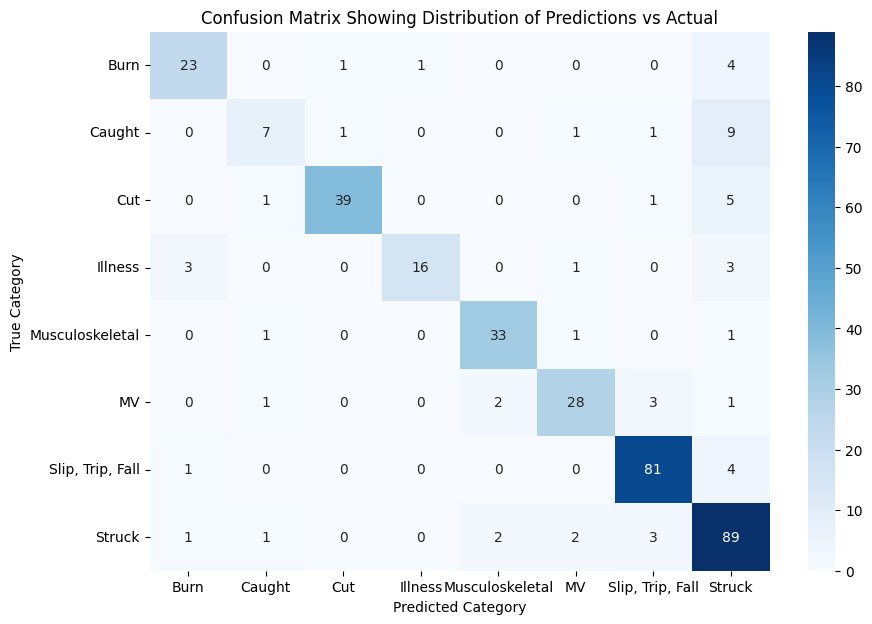

In [ ]:
best_params = grid_search.best_params_
best_model = grid_search.best_estimator_
print(f"Best Parameters: {best_params}")
y_pred_tuned = best_model.predict(X_test_vec)

accuracy_tuned = accuracy_score(y_test, y_pred_tuned)
print(f"Tuned Accuracy (%): {accuracy_tuned}", '\n')

# Create the confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Plot the confusion matrix using seaborn
plt.figure(figsize=(10, 7))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=data['Category'].unique(),
            yticklabels=data['Category'].unique())
plt.xlabel('Predicted Category')
plt.ylabel('True Category')
plt.title(f'Confusion Matrix Showing Distribution of Predictions vs Actual')
plt.show()

In [ ]:
data['CategoryPredicted'] = best_model.predict(vectorizer.transform(data['InjuryDesc']))
data.head(10)

,ClaimID,Cause,NewCause,Category,Subcategory,InjuryDesc,CategoryPredicted
0,369FL20210013037,BURN - Chemicals,Burn - Chemical,Burn,Chemical,ee using chemical avistat used spray room may ...,Burn
1,369FL20210012780,BURN - Chemicals,Burn - Chemical,Burn,Chemical,ee cleaning classroom noticed inside cabinet c...,Burn
2,369FL20190011137,BURN - Chemicals,Burn - Chemical,Burn,Chemical,friday may 29 2020 custodial staff waxing buff...,Burn
3,369FL20180009797,BURN - Chemicals,Burn - Chemical,Burn,Chemical,ee manually measure disinfectant sanitizer liq...,Burn
4,369FL20180008676,BURN - Chemicals,Burn - Chemical,Burn,Chemical,maria inside milkbox counting milk another cow...,Burn
5,369FL20170007824,BURN - Chemicals,Burn - Chemical,Burn,Chemical,ee cleaning wall cleaning chemical spray bottl...,Burn
6,369FL20170007581,BURN - Chemicals,Burn - Chemical,Burn,Chemical,iw unaware battery acid leaking walkie talkie ...,Burn
7,369FL20130001808,BURN - Chemicals,Burn - Chemical,Burn,Chemical,employee using backpack blower gas leaked blow...,Burn
8,369FL20220014124,"MISC - Absorption, Ingestion, Inhalation",Burn - Chemical,Burn,Chemical,ee cleaning toilet chemical splashed eye,Burn
9,369FL20220013683,"MISC - Absorption, Ingestion, Inhalation",Burn - Chemical,Burn,Chemical,ee stripping floor pulled chemical located buc...,Burn


Category: Burn 

Best Parameters: {'C': 10, 'gamma': 0.1, 'kernel': 'rbf'}
Subcategory Prediction Accuracy: 0.918918918918919


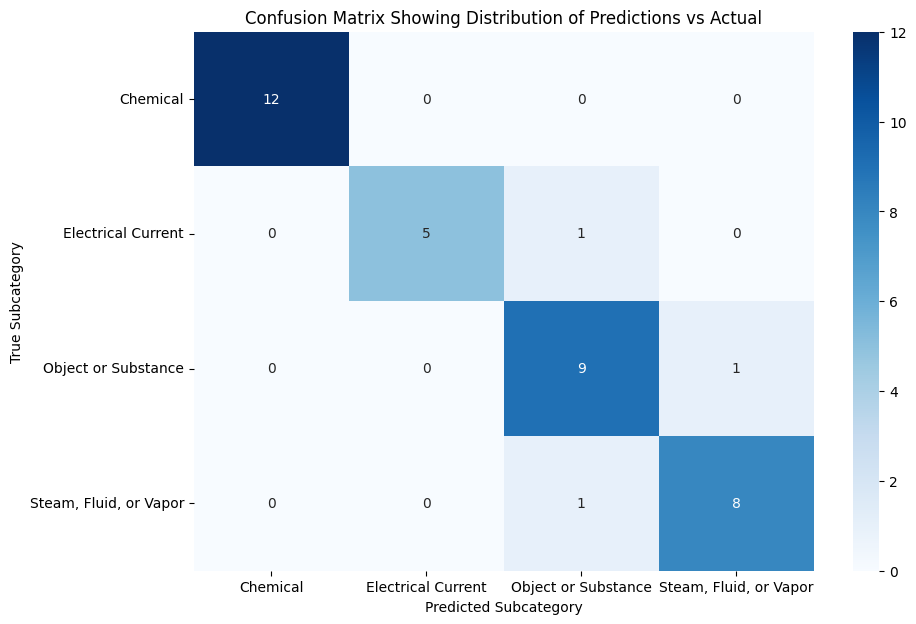

Category: Caught 

Best Parameters: {'C': 1, 'gamma': 'scale', 'kernel': 'linear'}
Subcategory Prediction Accuracy: 0.7333333333333333


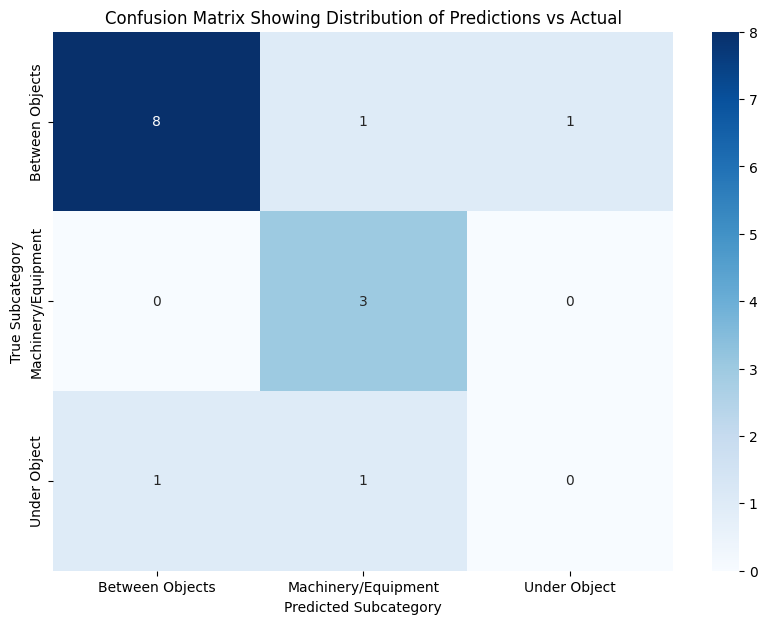

Category: Cut 

Best Parameters: {'C': 10, 'gamma': 'scale', 'kernel': 'linear'}
Subcategory Prediction Accuracy: 0.8648648648648649


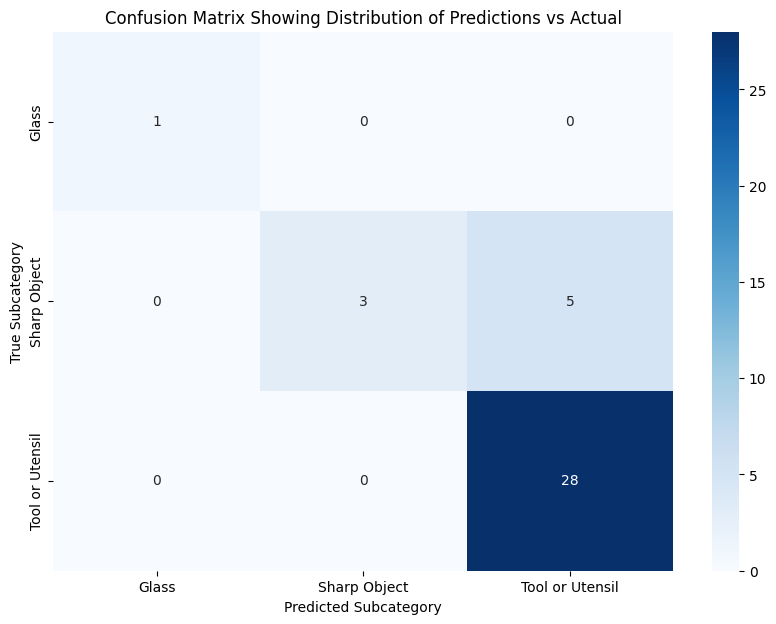

Category: Illness 

Best Parameters: {'C': 10, 'gamma': 'scale', 'kernel': 'linear'}
Subcategory Prediction Accuracy: 0.7


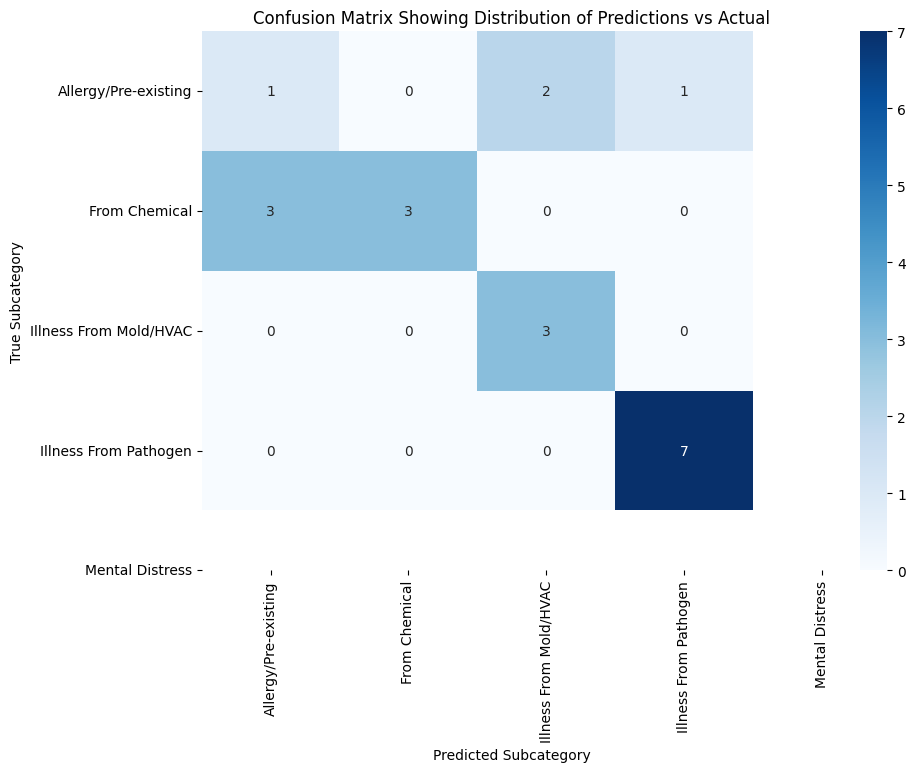

Category: Musculoskeletal 

Best Parameters: {'C': 10, 'gamma': 'scale', 'kernel': 'linear'}
Subcategory Prediction Accuracy: 0.868421052631579


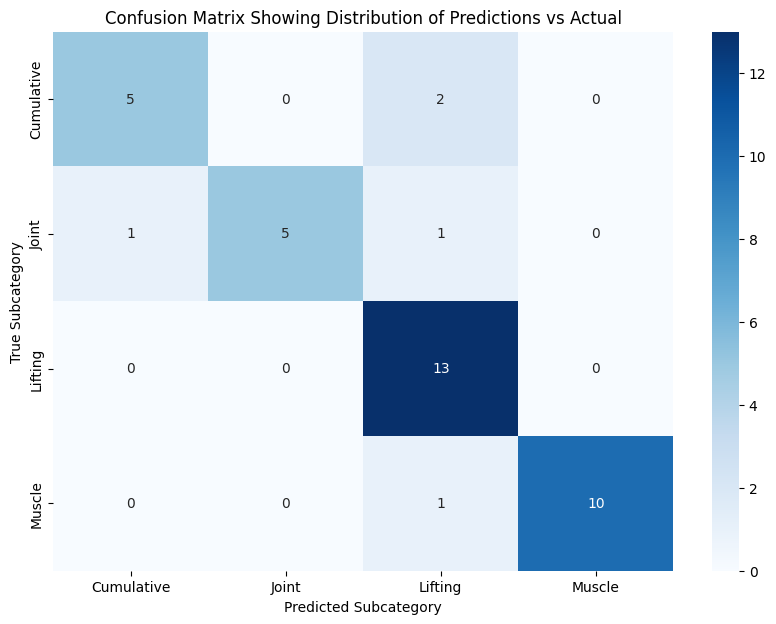

Category: MV 



/usr/local/lib/python3.11/dist-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 3 members, which is less than n_splits=5.
  warnings.warn(


Best Parameters: {'C': 10, 'gamma': 'scale', 'kernel': 'linear'}
Subcategory Prediction Accuracy: 0.9285714285714286


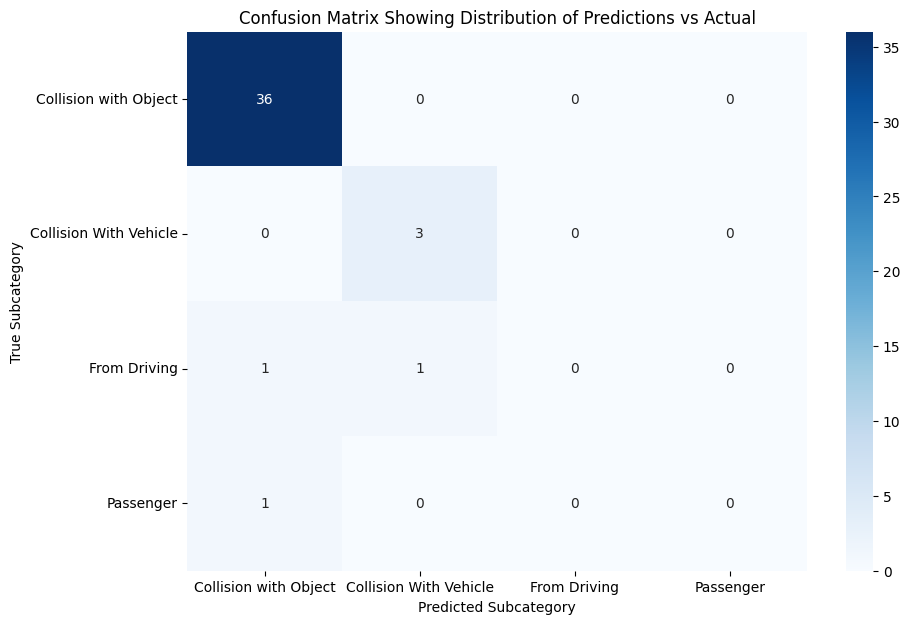

Category: Slip, Trip, Fall 

Best Parameters: {'C': 10, 'gamma': 0.1, 'kernel': 'rbf'}
Subcategory Prediction Accuracy: 0.8160919540229885


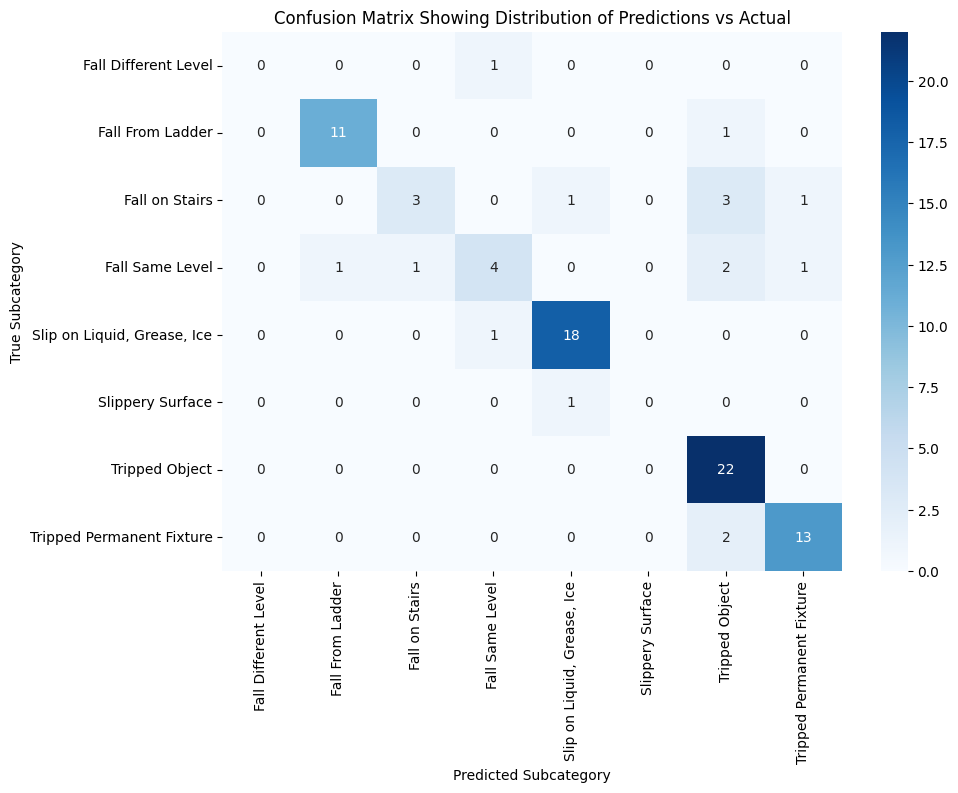

Category: Struck 

Best Parameters: {'C': 10, 'gamma': 'scale', 'kernel': 'linear'}
Subcategory Prediction Accuracy: 0.8686868686868687


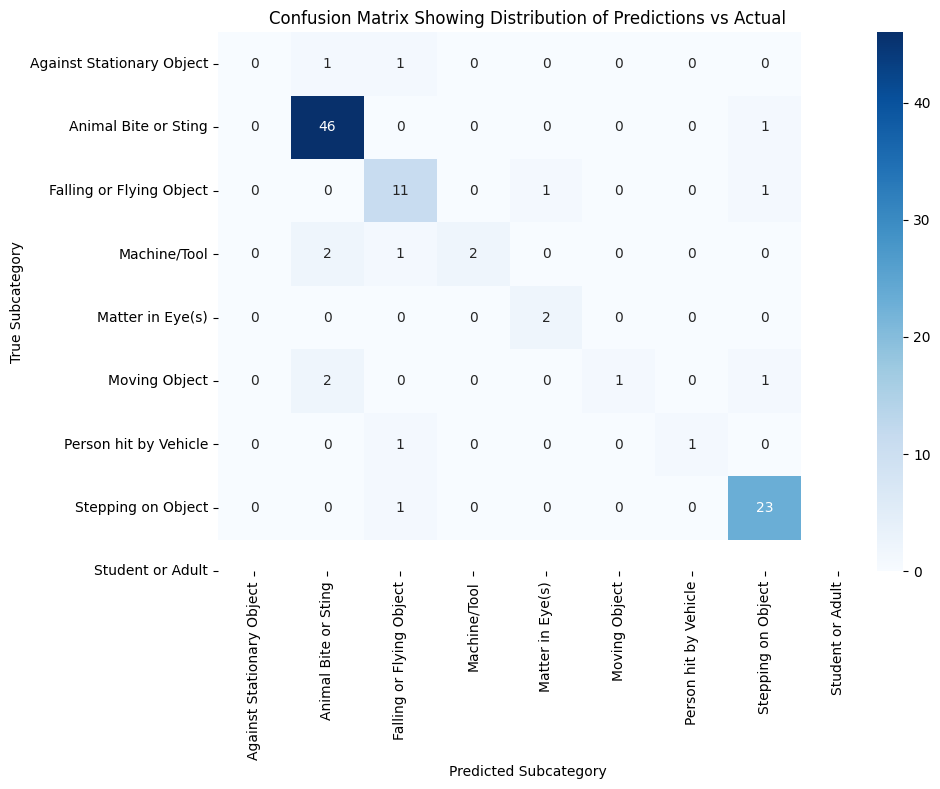

In [ ]:
category_dfs = {} # Empty dictionary for dataframes of each category
category_models = {}

for cat in data['Category'].unique():
    print(f"Category: {cat}",'\n')

    # Assuming 'svm_pred' is your DataFrame with predictions
    filtered = data[data['Category'] == cat]

    X_filtered = filtered['InjuryDesc']  # Features for subcategory prediction
    y_filtered = filtered['Subcategory']  # Target variable for subcategory

    # Split the data into training and testing sets
    X_filtered_train, X_filtered_test, y_filtered_train, y_filtered_test = train_test_split(
        X_filtered, y_filtered, test_size=0.2, random_state=42
    )

    # Vectorize the text data
    X_filtered_train_vec = vectorizer.transform(X_filtered_train)
    X_filtered_test_vec = vectorizer.transform(X_filtered_test)

    # Create and train the SVM model
    svm_sub_model = SVC(kernel='rbf', C=10, gamma=0.1)  # Adjust parameters as needed
    svm_sub_model.fit(X_filtered_train_vec, y_filtered_train)

    grid_search = GridSearchCV(svm_sub_model, param_grid, cv=5, scoring='accuracy')
    grid_search.fit(X_filtered_train_vec, y_filtered_train)

    best_params = grid_search.best_params_
    best_model = grid_search.best_estimator_
    print(f"Best Parameters: {best_params}")

    # Store the best model in the dictionary
    category_models[cat] = best_model

    # Make predictions on the test set
    y_filtered_pred = best_model.predict(X_filtered_test_vec)

    # Store the DataFrame in the dictionary
    category_dfs[cat] = filtered

    # Evaluate the model's accuracy
    accuracy_sub = accuracy_score(y_filtered_test, y_filtered_pred)
    print(f"Subcategory Prediction Accuracy: {accuracy_sub}")

    # Create the confusion matrix
    cm = confusion_matrix(y_filtered_test, y_filtered_pred)

    # Plot the confusion matrix using seaborn
    plt.figure(figsize=(10, 7))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=filtered['Subcategory'].unique(),
                yticklabels=filtered['Subcategory'].unique())

    plt.xlabel('Predicted Subcategory')
    plt.ylabel('True Subcategory')
    plt.title(f'Confusion Matrix Showing Distribution of Predictions vs Actual')
    plt.show()

In [ ]:
# Create a new column for predicted subcategory
data['Predicted_Subcategory'] = data.apply(lambda row: category_models.get(row['CategoryPredicted'], None).predict(vectorizer.transform([row['InjuryDesc']]))[0] if category_models.get(row['CategoryPredicted'], None) else None, axis=1)

data

,ClaimID,Cause,NewCause,Category,Subcategory,InjuryDesc,CategoryPredicted,Predicted_Subcategory
0,369FL20210013037,BURN - Chemicals,Burn - Chemical,Burn,Chemical,ee using chemical avistat used spray room may ...,Burn,Chemical
1,369FL20210012780,BURN - Chemicals,Burn - Chemical,Burn,Chemical,ee cleaning classroom noticed inside cabinet c...,Burn,Chemical
2,369FL20190011137,BURN - Chemicals,Burn - Chemical,Burn,Chemical,friday may 29 2020 custodial staff waxing buff...,Burn,Chemical
3,369FL20180009797,BURN - Chemicals,Burn - Chemical,Burn,Chemical,ee manually measure disinfectant sanitizer liq...,Burn,Chemical
4,369FL20180008676,BURN - Chemicals,Burn - Chemical,Burn,Chemical,maria inside milkbox counting milk another cow...,Burn,Chemical
...,...,...,...,...,...,...,...,...
1855,369FL20230015652,FALL - On Same Level,Struck - Student or Adult,Struck,Student or Adult,mr ponder several employee trying break fight ...,Struck,Student or Adult
1856,369FL20210012396,FALL - On Same Level,Struck - Student or Adult,Struck,Student or Adult,ee responded call fight bus loop attempted get...,Struck,Student or Adult
1857,369FL20200011342,STRUCK - Falling or Flying Object,Struck - Student or Adult,Struck,Student or Adult,dismissal bus student threw clipboard hit head...,Struck,Student or Adult
1858,369FL20160005801,STRUCK - Falling or Flying Object,Struck - Student or Adult,Struck,Student or Adult,student bus horse playing throwing object bus ...,Struck,Student or Adult


In [ ]:
new_data = pd.read_excel('/content/drive/MyDrive/wclaims.xlsx')
new_data.head()

,WorkLoc#,WL,WorkLocNm,LocRef,ClaimID,FirstName,LastName,Status,Type,PrlClassCd,...,part(short),PartSecondary,PartRef,Cause,Cause(short),Cause(secondary),InjuryDesc,TotPTD,TotRsvBal,TotIncd
0,6.221000e+09,6221.0,DRIVERS AND MONITORS,Transportation (Driver and Admin),369FL20240017451,TOM,RAPP,O,MO,7383,...,LE,Knee,Lower Extremity,FALL - On Stairs,FALL,On Stairs,Slipped while boarding the bus and fell on rig...,0.0,850.0,850.0
1,6.901000e+09,6901.0,MAINTENANCE/NORTHWEST,Northwest Area Maint,369FL20240017450,KENT,GAINOUS,O,LT,9101,...,UE,Hand,Upper Extremity,STRUCK - Hand Tool or Machine In Use,STRUCK,Hand Tool or Machine In Use,BLD 400 - RM 420 - repairing lose column/pole ...,0.0,0.0,0.0
2,8.910000e+08,891.0,MCCOY ELEMENTARY,McCoy Elementary,369FL20240017452,LIZETTE,ADORNO,O,MO,8868,...,MULTIPLE,Multiple Body Parts,NaN,"FALL - Fall, Slip, Trip, NOC",FALL,"Fall, Slip, Trip, NOC",Employee was doing car area duty when she step...,0.0,850.0,850.0
3,1.553000e+09,1553.0,MILLENNIA ELEMENTARY,Millennia Elementary,369FL20240017449,ROMENA,YUSUF,O,LT,8868,...,LE,Foot,Lower Extremity,FALL - On Same Level,FALL,On Same Level,While walking through the hallway on the secon...,0.0,0.0,0.0
4,2.120000e+08,212.0,OAKSHIRE ELEMENTARY,Oakshire Elementary,369FL20240017447,EDWARD,ALICEA,O,MO,8868,...,LE,Knee,Lower Extremity,STRUCK - Fellow Worker or Patient,STRUCK,Fellow Worker or Patient,AS PER MR. ALICEA DESCRIPTION: STUDENT KICK HI...,0.0,850.0,850.0


In [ ]:
# Apply the same cleaning function to the new data
new_data['InjuryDesc'] = new_data['InjuryDesc'].apply(clean_text)

# Vectorize the new data using the same vectorizer from the previous steps
new_data_vec = vectorizer.transform(new_data['InjuryDesc'])

# Predict the category for the new data using the trained best_model
new_data['Predicted_Category'] = svm_model.predict(new_data_vec)

# Display the new data with the predicted columns
new_data.head()

,WorkLoc#,WL,WorkLocNm,LocRef,ClaimID,FirstName,LastName,Status,Type,PrlClassCd,...,PartSecondary,PartRef,Cause,Cause(short),Cause(secondary),InjuryDesc,TotPTD,TotRsvBal,TotIncd,Predicted_Category
0,6.221000e+09,6221.0,DRIVERS AND MONITORS,Transportation (Driver and Admin),369FL20240017451,TOM,RAPP,O,MO,7383,...,Knee,Lower Extremity,FALL - On Stairs,FALL,On Stairs,slipped boarding bus fell right knee,0.0,850.0,850.0,"Slip, Trip, Fall"
1,6.901000e+09,6901.0,MAINTENANCE/NORTHWEST,Northwest Area Maint,369FL20240017450,KENT,GAINOUS,O,LT,9101,...,Hand,Upper Extremity,STRUCK - Hand Tool or Machine In Use,STRUCK,Hand Tool or Machine In Use,bld 400 rm 420 repairing lose column pole insi...,0.0,0.0,0.0,Struck
2,8.910000e+08,891.0,MCCOY ELEMENTARY,McCoy Elementary,369FL20240017452,LIZETTE,ADORNO,O,MO,8868,...,Multiple Body Parts,NaN,"FALL - Fall, Slip, Trip, NOC",FALL,"Fall, Slip, Trip, NOC",employee car area duty stepped curb fell hit k...,0.0,850.0,850.0,"Slip, Trip, Fall"
3,1.553000e+09,1553.0,MILLENNIA ELEMENTARY,Millennia Elementary,369FL20240017449,ROMENA,YUSUF,O,LT,8868,...,Foot,Lower Extremity,FALL - On Same Level,FALL,On Same Level,walking hallway second floor room 234 fell lan...,0.0,0.0,0.0,"Slip, Trip, Fall"
4,2.120000e+08,212.0,OAKSHIRE ELEMENTARY,Oakshire Elementary,369FL20240017447,EDWARD,ALICEA,O,MO,8868,...,Knee,Lower Extremity,STRUCK - Fellow Worker or Patient,STRUCK,Fellow Worker or Patient,per mr alicea description student kick right k...,0.0,850.0,850.0,Struck


In [ ]:
# Predict the subcategory for the new data using the appropriate subcategory model
new_data['Predicted_Subcategory'] = new_data.apply(lambda row: category_models.get(row['Predicted_Category'], None).predict(vectorizer.transform([row['InjuryDesc']]))[0] if category_models.get(row['Predicted_Category'], None) else None, axis=1)
new_data.head(10)

,WorkLoc#,WL,WorkLocNm,LocRef,ClaimID,FirstName,LastName,Status,Type,PrlClassCd,...,PartRef,Cause,Cause(short),Cause(secondary),InjuryDesc,TotPTD,TotRsvBal,TotIncd,Predicted_Category,Predicted_Subcategory
0,6.221000e+09,6221.0,DRIVERS AND MONITORS,Transportation (Driver and Admin),369FL20240017451,TOM,RAPP,O,MO,7383,...,Lower Extremity,FALL - On Stairs,FALL,On Stairs,slipped boarding bus fell right knee,0.0,850.0,850.0,"Slip, Trip, Fall","Slip on Liquid, Grease, Ice"
1,6.901000e+09,6901.0,MAINTENANCE/NORTHWEST,Northwest Area Maint,369FL20240017450,KENT,GAINOUS,O,LT,9101,...,Upper Extremity,STRUCK - Hand Tool or Machine In Use,STRUCK,Hand Tool or Machine In Use,bld 400 rm 420 repairing lose column pole insi...,0.0,0.0,0.0,Struck,Falling or Flying Object
2,8.910000e+08,891.0,MCCOY ELEMENTARY,McCoy Elementary,369FL20240017452,LIZETTE,ADORNO,O,MO,8868,...,NaN,"FALL - Fall, Slip, Trip, NOC",FALL,"Fall, Slip, Trip, NOC",employee car area duty stepped curb fell hit k...,0.0,850.0,850.0,"Slip, Trip, Fall",Tripped Permanent Fixture
3,1.553000e+09,1553.0,MILLENNIA ELEMENTARY,Millennia Elementary,369FL20240017449,ROMENA,YUSUF,O,LT,8868,...,Lower Extremity,FALL - On Same Level,FALL,On Same Level,walking hallway second floor room 234 fell lan...,0.0,0.0,0.0,"Slip, Trip, Fall",Tripped Permanent Fixture
4,2.120000e+08,212.0,OAKSHIRE ELEMENTARY,Oakshire Elementary,369FL20240017447,EDWARD,ALICEA,O,MO,8868,...,Lower Extremity,STRUCK - Fellow Worker or Patient,STRUCK,Fellow Worker or Patient,per mr alicea description student kick right k...,0.0,850.0,850.0,Struck,Student or Adult
5,2.320000e+08,232.0,WEST CREEK ELEMENTARY,West Creek Elementary,369FL20240017448,JENNIFER,CASTRO,O,MO,8868,...,NaN,STRUCK - Fellow Worker or Patient,STRUCK,Fellow Worker or Patient,trying prevent student physically attacking yo...,0.0,850.0,850.0,Struck,Student or Adult
6,2.170000e+08,217.0,CAMELOT ELEMENTARY,Camelot Elementary,369FL20240017446,ANA,RODRIGUEZ SANTOS,O,MO,9101,...,NaN,STRUCK - Fellow Worker or Patient,STRUCK,Fellow Worker or Patient,classroom walking student desk way desk grabbe...,0.0,850.0,850.0,Struck,Falling or Flying Object
7,1.561000e+09,1561.0,MAGNOLIA SCHOOL,Magnolia School (K-12),369FL20240017443,VALDETE,BYRD,O,MO,9101,...,Head,"STRUCK - Struck or Injured, NOC",STRUCK,"Struck or Injured, NOC",date time staff report pe student open hand hi...,0.0,850.0,850.0,Struck,Student or Adult
8,1.471000e+09,1471.0,HORIZON WEST HIGH SCHOOL,Horizon High,369FL20240017444,WENDY,NAIL,O,MO,8868,...,Lower Extremity,"FALL - Fall, Slip, Trip, NOC",FALL,"Fall, Slip, Trip, NOC",fell curb broke ankle grad bash universal stud...,0.0,850.0,850.0,"Slip, Trip, Fall",Tripped Object
9,1.210000e+08,121.0,EDGEWATER HIGH,Edgewater High,369FL20240017445,DANIEL,MCCABE,O,MO,9101,...,Head,"STRUCK - Struck or Injured, NOC",STRUCK,"Struck or Injured, NOC",hit head corner vcr shelf complaining abrasion...,0.0,850.0,850.0,Struck,Falling or Flying Object


<ipython-input-33-8502d91650c7>:17: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  filtered_data['Month_Year'] = filtered_data['AccDt'].dt.to_period('M')


Monthly Counts of 'student or adult' Predicted Subcategories (Starting 7/1/2024):
            Count
Month_Year       
2024-08        43
2024-09        59
2024-10        57
2024-11        55
2024-12        26
2025-01        41
2025-02        50
2025-03        27
2025-04        39
Total:  397


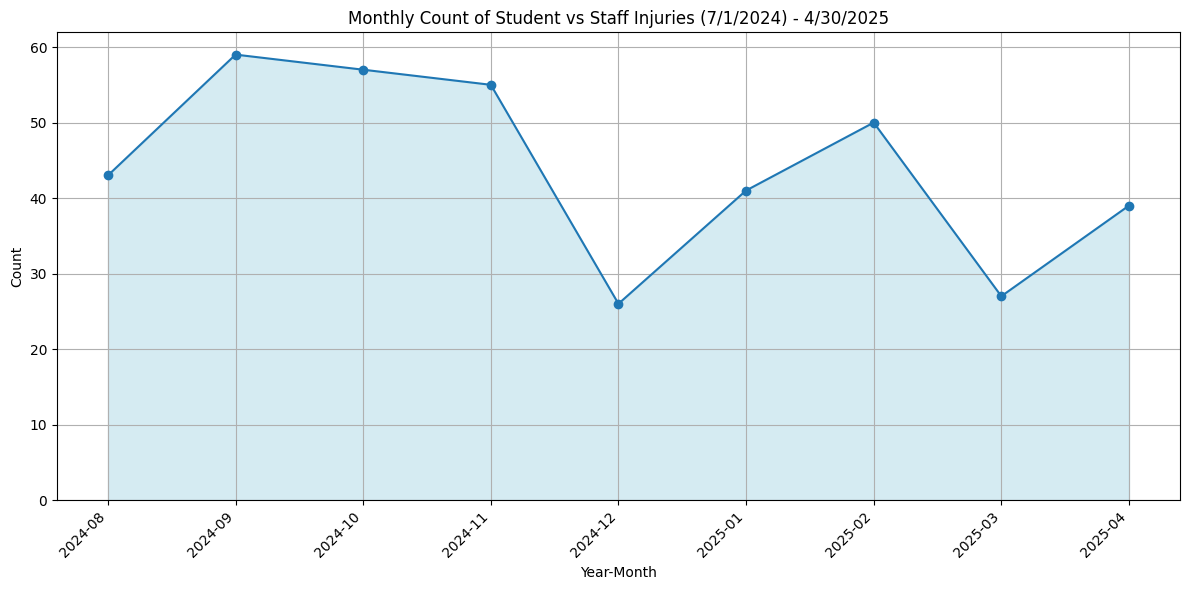

In [ ]:
# 1. Ensure 'AccDt' is in datetime format
# Use errors='coerce' to turn unparseable dates into NaT (Not a Time)
new_data['AccDt'] = pd.to_datetime(new_data['AccDt'], errors='coerce')

# Remove rows where 'AccDt' could not be parsed
new_data.dropna(subset=['AccDt'], inplace=True)

# 2. Filter for the specified date and predicted subcategory
start_date = pd.to_datetime('7/1/2024')
filtered_data = new_data[
    (new_data['Predicted_Subcategory'] == 'Student or Adult') &
    (new_data['AccDt'] >= start_date)
]

# 3. Extract month and year and create a new column
# You can format this as 'YYYY-MM' for correct chronological sorting
filtered_data['Month_Year'] = filtered_data['AccDt'].dt.to_period('M')

# 4. Group and count
monthly_counts = filtered_data['Month_Year'].value_counts().sort_index()

# Convert Month_Year Period objects back to strings for plotting if needed,
# or handle Period objects directly if your matplotlib version supports it well.
monthly_counts.index = monthly_counts.index.astype(str)

# Display the table of monthly counts
print("Monthly Counts of 'student or adult' Predicted Subcategories (Starting 7/1/2024):")
print(monthly_counts.to_frame(name='Count'))
print('Total: ', sum(monthly_counts))


# 5. Plot the line graph
plt.figure(figsize=(12, 6))

# Plot the line
plt.plot(monthly_counts.index, monthly_counts.values, marker='o', linestyle='-', label='Count')

# Fill the area under the line
plt.fill_between(monthly_counts.index, 0, monthly_counts.values, color='lightblue', alpha=0.5) # alpha for transparency

plt.xlabel('Year-Month')
plt.ylabel('Count')
plt.title('Monthly Count of Student vs Staff Injuries (7/1/2024) - 4/30/2025')
plt.xticks(rotation=45, ha='right') # Rotate labels for readability

# Set the y-axis limit to start at 0
plt.ylim(bottom=0)

plt.tight_layout() # Adjust layout to prevent labels overlapping
plt.grid(True)
plt.show()

In [ ]:
from google.colab import files

# Save the filtered DataFrame to a CSV file
filtered_data.to_csv('studentvsadultinjuries.csv', index=False)

# Download the file
files.download('studentvsadultinjuries.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Save Model

In [ ]:
import pickle
import os

# Define a directory to save your models
model_dir = '/content/drive/MyDrive/trained_models' # Or any preferred path
os.makedirs(model_dir, exist_ok=True) # Create the directory if it doesn't exist

# Save the TfidfVectorizer
with open(os.path.join(model_dir, 'tfidf_vectorizer.pkl'), 'wb') as f:
    pickle.dump(vectorizer, f)

# Save the best category model (best_model after the first GridSearchCV)
# Make sure you are saving the final best category model
with open(os.path.join(model_dir, 'category_model.pkl'), 'wb') as f:
    pickle.dump(best_model, f)

# Save the dictionary of subcategory models
with open(os.path.join(model_dir, 'subcategory_models.pkl'), 'wb') as f:
    pickle.dump(category_models, f)

print(f"Models and vectorizer saved to {model_dir}")

In [ ]:
import pandas as pd
import pickle
import os
import re
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

# Assuming nltk downloads are already done or will be done once in the environment
# nltk.download('stopwords')
# nltk.download('wordnet')

# Reuse the existing clean_text function (copy-paste it or import if in a module)
def clean_text(text):
    text = str(text)
    text = text.lower()
    text = re.sub(r"[^a-zA-Z0-9]", " ", text)
    text = re.sub(r"\s+", " ", text)
    stop_words = set(stopwords.words("english"))
    lemmatizer = WordNetLemmatizer()
    tokens = text.split()
    tokens = [lemmatizer.lemmatize(word) for word in tokens if word not in stop_words]
    return " ".join(tokens)

# Reuse the prediction function (copy-paste it or import if in a module)
def predict_category_and_subcategory(dataframe, text_column_name, vectorizer, category_model, subcategory_models):
    """
    Predicts category and subcategory for text data in a DataFrame.

    Args:
        dataframe (pd.DataFrame): The input DataFrame.
        text_column_name (str): The name of the column containing the text descriptions.
        vectorizer (TfidfVectorizer): The trained TF-IDF vectorizer.
        category_model: The trained model for category prediction.
        subcategory_models (dict): A dictionary mapping categories to their
                                   corresponding trained subcategory models.

    Returns:
        pd.DataFrame: The DataFrame with 'Predicted_Category' and
                      'Predicted_Subcategory' columns added.
    """
    dataframe['Cleaned_Text'] = dataframe[text_column_name].apply(clean_text)
    text_vec = vectorizer.transform(dataframe['Cleaned_Text'])
    dataframe['Predicted_Category'] = category_model.predict(text_vec)
    dataframe['Predicted_Subcategory'] = dataframe.apply(
        lambda row: subcategory_models.get(row['Predicted_Category'], None).predict(vectorizer.transform([row['Cleaned_Text']]))[0]
        if subcategory_models.get(row['Predicted_Category'], None) else None,
        axis=1
    )
    dataframe = dataframe.drop(columns=['Cleaned_Text'])
    return dataframe

# Define the directory where your models are saved
model_dir = '/content/drive/MyDrive/trained_models' # Must match the saving path

# Load the saved vectorizer, category model, and subcategory models
try:
    with open(os.path.join(model_dir, 'tfidf_vectorizer.pkl'), 'rb') as f:
        loaded_vectorizer = pickle.load(f)

    with open(os.path.join(model_dir, 'category_model.pkl'), 'rb') as f:
        loaded_category_model = pickle.load(f)

    with open(os.path.join(model_dir, 'subcategory_models.pkl'), 'rb') as f:
        loaded_subcategory_models = pickle.load(f)

    print("Models and vectorizer loaded successfully.")

except FileNotFoundError:
    print(f"Error: Model files not found in {model_dir}. Please ensure you have saved them.")
    # Handle the error appropriately, e.g., exit the script or raise an exception

# Now you can use the loaded objects with your prediction function
# Example: Load new data and make predictions
# new_data_to_predict = pd.read_excel('/content/drive/MyDrive/some_new_data.xlsx')
# predicted_data = predict_category_and_subcategory(
#     new_data_to_predict.copy(),
#     'InjuryDesc', # Assuming 'InjuryDesc' is the text column name
#     loaded_vectorizer,
#     loaded_category_model,
#     loaded_subcategory_models
# )
# print(predicted_data.head())